# UD English EWT Dataset EDA

Exploratory Data Analysis of the official Universal Dependencies English Web Treebank dataset.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import statistics as stats

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_dir = Path("../data")
train_path = data_dir / "train.conllu"
dev_path = data_dir / "dev.conllu"
test_path = data_dir / "test.conllu"

In [3]:
# Verify whether the files we are going to use exist or not

print(train_path.exists())
print(dev_path.exists())
print(test_path.exists())

True
True
True


In [4]:
import sys
sys.path.insert(0, str(Path("..").resolve()))

from src.dataset_loader import load_conllu

train = load_conllu(train_path)
dev = load_conllu(dev_path)
test = load_conllu(test_path)

# Sanity check: print the number of sentences in each dataset
print(len(train))
print(len(dev))
print(len(test))

12544
2001
2077


In [5]:
# Helper function to get all tokens from a list of sentences
def get_tokens(sentences):
    return [token for sentence in sentences for token in sentence]

train_tokens = get_tokens(train)
dev_tokens = get_tokens(dev)
test_tokens = get_tokens(test)

In [6]:

split_data = {
    "Train": (train, train_tokens),
    "Dev": (dev, dev_tokens),
    "Test": (test, test_tokens),
}

statistics = []
for split, (sentences, tokens) in split_data.items():
    statistics.append(
        {
            "Split": split,
            "Sentences": len(sentences),
            "Tokens": len(tokens),
            "Vocabulary Size": len(set(word for word, tag in tokens)),
            "POS Tags": len(set(tag for word, tag in tokens)),
        }
    )

statistics_df = pd.DataFrame(statistics)
statistics_df.style.hide(axis="index")

Split,Sentences,Tokens,Vocabulary Size,POS Tags
Train,12544,204578,19674,17
Dev,2001,25148,5493,17
Test,2077,25094,5629,17


In [7]:
train_lengths = [len(sentence) for sentence in train]
dev_lengths = [len(sentence) for sentence in dev]
test_lengths = [len(sentence) for sentence in test]

length_rows = []
for split, lengths in (
    ("Train", train_lengths),
    ("Dev", dev_lengths),
    ("Test", test_lengths),
):
    length_rows.append(
        {
            "Split": split,
            "Mean": stats.mean(lengths),
            "Median": stats.median(lengths),
            "Minimum": min(lengths),
            "Maximum": max(lengths),
            "Std Dev": stats.stdev(lengths),
        }
    )

sentence_length_df = pd.DataFrame(length_rows)
sentence_length_df.style.hide(axis="index")

Split,Mean,Median,Minimum,Maximum,Std Dev
Train,16.308833,14.000000,1,159,12.401967
Dev,12.567716,10.000000,1,75,10.416647
Test,12.081849,9.000000,1,81,10.605604


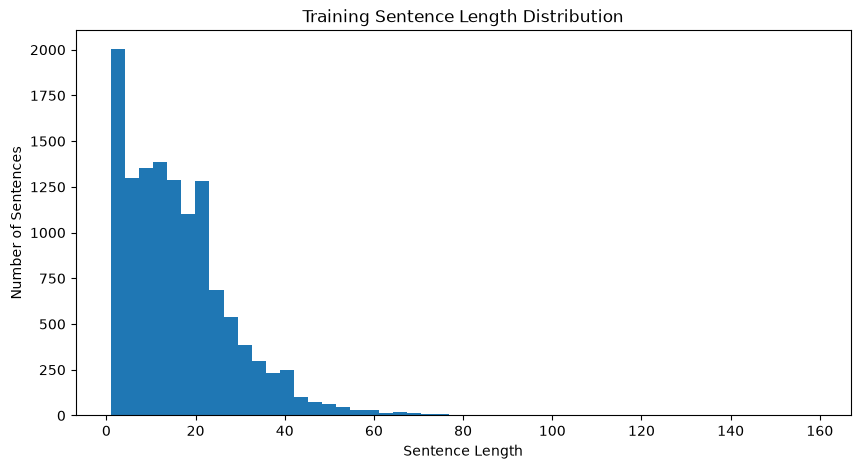

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(train_lengths, bins=50)

plt.xlabel("Sentence Length")
plt.ylabel("Number of Sentences")
plt.title("Training Sentence Length Distribution")

plt.show()

In [9]:
train_pos_counts = Counter(tag for word, tag in train_tokens)
dev_pos_counts = Counter(tag for word, tag in dev_tokens)
test_pos_counts = Counter(tag for word, tag in test_tokens)

upos_tags = sorted(
    set(train_pos_counts) | set(dev_pos_counts) | set(test_pos_counts)
)

upos_counts_df = pd.DataFrame(
    {
        "UPOS": upos_tags,
        "Train": [train_pos_counts[tag] for tag in upos_tags],
        "Dev": [dev_pos_counts[tag] for tag in upos_tags],
        "Test": [test_pos_counts[tag] for tag in upos_tags],
    }
)

upos_counts_df.style.hide(axis="index")

UPOS,Train,Dev,Test
ADJ,13136,1865,1788
ADP,17714,2038,2025
ADV,10172,1232,1191
AUX,12815,1567,1543
CCONJ,6687,780,736
DET,16299,1900,1897
INTJ,695,115,121
NOUN,34751,4210,4123
NUM,4126,383,542
PART,5748,647,649


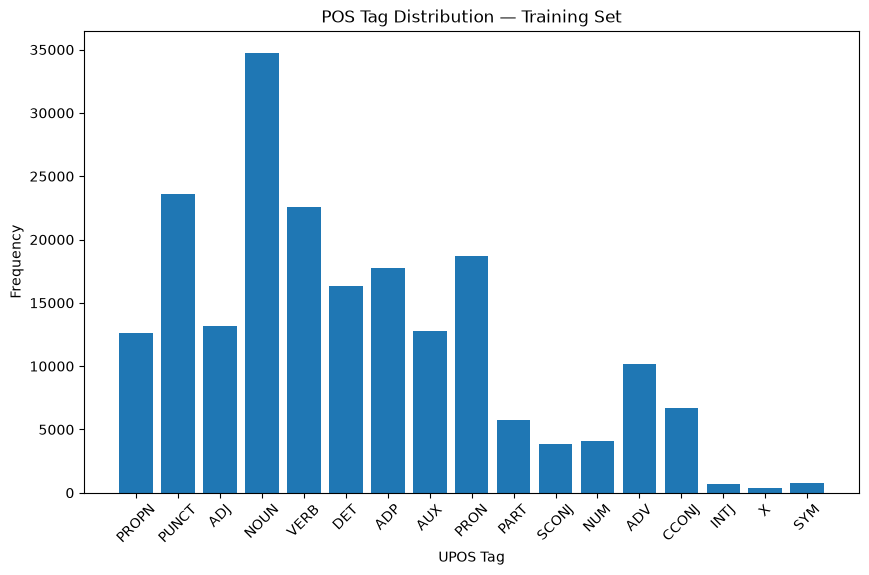

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    list(train_pos_counts.keys()),
    list(train_pos_counts.values()),
)

plt.xlabel("UPOS Tag")
plt.ylabel("Frequency")
plt.title("POS Tag Distribution — Training Set")
plt.xticks(rotation=45)

plt.show()

In [11]:
train_vocab = set(word for word, tag in train_tokens)

len(train_vocab)

19674

In [12]:
dev_vocab = set(word for word, tag in dev_tokens)
test_vocab = set(word for word, tag in test_tokens)

dev_unknown_types = dev_vocab - train_vocab
test_unknown_types = test_vocab - train_vocab

print("Unseen dev word types:", len(dev_unknown_types))
print("Unseen test word types:", len(test_unknown_types))

Unseen dev word types: 1661
Unseen test word types: 1836


In [13]:
dev_unknown_tokens = sum(
    word not in train_vocab for word, tag in dev_tokens
)
test_unknown_tokens = sum(
    word not in train_vocab for word, tag in test_tokens
)

dev_total_tokens = len(dev_tokens)
test_total_tokens = len(test_tokens)

unknown_token_rows = [
    {
        "Split": "Dev",
        "Total Tokens": dev_total_tokens,
        "Unknown Tokens": dev_unknown_tokens,
        "Unknown %": 100 * dev_unknown_tokens / dev_total_tokens,
    },
    {
        "Split": "Test",
        "Total Tokens": test_total_tokens,
        "Unknown Tokens": test_unknown_tokens,
        "Unknown %": 100 * test_unknown_tokens / test_total_tokens,
    },
]

unknown_token_df = pd.DataFrame(unknown_token_rows)
unknown_token_df.style.hide(axis="index")

Split,Total Tokens,Unknown Tokens,Unknown %
Dev,25148,2087,8.298871
Test,25094,2292,9.133657


In [14]:
word_tags = defaultdict(set)

for word, tag in train_tokens:
    word_tags[word].add(tag)

word_tags["run"]

{'ADJ', 'NOUN', 'VERB'}

In [15]:
ambiguous_rows = [
    {
        "Word": word,
        "Tags": ", ".join(sorted(tags)),
        "Number of Tags": len(tags),
    }
    for word, tags in word_tags.items()
    if len(tags) > 1
]

ambiguous_words_df = (
    pd.DataFrame(ambiguous_rows)
    .sort_values(["Number of Tags", "Word"], ascending=[False, True])
    .head(30)
)

ambiguous_words_df.style.hide(axis="index")

Word,Tags,Number of Tags
a,"ADP, ADV, AUX, CCONJ, DET, NOUN, NUM, PART",8
to,"ADP, ADV, DET, NOUN, PART, SCONJ, VERB, X",8
A,"ADP, DET, NOUN, NUM, PROPN, SYM, X",7
in,"ADJ, ADP, ADV, AUX, NOUN, SCONJ, X",7
on,"ADJ, ADP, ADV, NOUN, NUM, PROPN, SCONJ",7
back,"ADJ, ADP, ADV, NOUN, VERB, X",6
like,"ADJ, ADP, ADV, INTJ, SCONJ, VERB",6
out,"ADJ, ADP, ADV, NOUN, PRON, X",6
s,"AUX, NOUN, PART, PRON, VERB, X",6
Like,"ADJ, ADP, INTJ, SCONJ, VERB",5


In [16]:
word_tag_counts = defaultdict(Counter)

for word, tag in train_tokens:
    word_tag_counts[word][tag] += 1

frequency_ambiguity_rows = [
    {
        "Word": word,
        "Tag Counts": ", ".join(
            f"{tag}: {count}" for tag, count in counts.most_common()
        ),
        "Number of Tags": len(counts),
        "Total Occurrences": sum(counts.values()),
    }
    for word, counts in word_tag_counts.items()
    if len(counts) > 1
]

frequency_ambiguity_df = (
    pd.DataFrame(frequency_ambiguity_rows)
    .sort_values(
        ["Number of Tags", "Total Occurrences", "Word"],
        ascending=[False, False, True],
    )
    .head(30)
)

frequency_ambiguity_df.style.hide(axis="index")

Word,Tag Counts,Number of Tags,Total Occurrences
to,"PART: 3227, ADP: 1785, SCONJ: 54, ADV: 6, VERB: 1, DET: 1, X: 1, NOUN: 1",8,5076
a,"DET: 3589, ADP: 7, NUM: 4, NOUN: 4, ADV: 2, CCONJ: 1, PART: 1, AUX: 1",8,3609
in,"ADP: 2708, ADV: 106, SCONJ: 86, NOUN: 8, ADJ: 1, AUX: 1, X: 1",7,2911
on,"ADP: 1100, SCONJ: 59, ADV: 48, ADJ: 6, NOUN: 1, NUM: 1, PROPN: 1",7,1216
A,"DET: 151, PROPN: 7, NOUN: 6, SYM: 5, X: 2, NUM: 1, ADP: 1",7,173
out,"ADP: 311, ADV: 117, NOUN: 8, PRON: 3, X: 2, ADJ: 2",6,443
like,"ADP: 152, VERB: 136, SCONJ: 82, INTJ: 14, ADJ: 8, ADV: 1",6,393
back,"ADV: 172, NOUN: 33, ADP: 17, ADJ: 5, VERB: 4, X: 1",6,232
s,"PART: 71, AUX: 69, X: 9, PRON: 5, VERB: 3, NOUN: 2",6,159
of,"ADP: 3456, SCONJ: 128, ADV: 3, CCONJ: 1, AUX: 1",5,3589


## EDA Conclusions

- The training split is the largest, with 12,544 sentences and 204,578 tokens. The development split contains 2,001 sentences and 25,148 tokens, while the test split contains 2,077 sentences and 25,094 tokens.
- In the training data, NOUN is the most frequent POS tag with 34,751 tokens. X is the least frequent with 400 tokens, so the tag distribution is not balanced.
- Mean sentence length is 16.31 tokens in training, 12.57 in development, and 12.08 in test. Training sentences are therefore about four tokens longer on average than development and test sentences.
- The training vocabulary contains 19,674 distinct word types. There are 1,661 word types in development and 1,836 word types in test that never occur in training.
- Unknown words account for 8.30% of development tokens and 9.13% of test tokens. This means evaluation includes a meaningful amount of vocabulary that cannot be handled by direct training-set lookup.
- The training data contains 1,973 word types that occur with more than one POS tag. Common ambiguous examples include `to`, `a`, `in`, `on`, and `run`.
- The frequency-aware ambiguity analysis shows that ambiguity is often highly unbalanced: for example, `to` occurs mainly as `PART` and `ADP`, while its other observed tags are rare. A word-to-single-tag dictionary would lose this distributional information.
- Unknown words mean that an HMM or BiLSTM cannot rely exclusively on memorized word-to-tag mappings; the later models need handling for unseen vocabulary, such as an unknown-word representation or character-level features.
- Ambiguous words demonstrate why context matters for POS tagging. The correct tag for a word such as `run` cannot always be determined from the word alone, so sequence context and neighboring tokens should help disambiguate it.